# 01. Generative AI vs Discriminative Models

## Aim
To study Generative AI and compare a discriminative classifier with a generative autoencoder.

## Theory
A discriminative model learns a decision boundary and predicts labels. A generative model learns the structure of data and can reconstruct or create samples. This practical uses the handwritten digits dataset as a compact MNIST-style dataset.

## Expected Learning
Understand the difference between deciding what an input is and learning how the input itself is formed.

Training samples: (1437, 64)
Testing samples : (360, 64)
Discriminative model accuracy: 0.9194
Generative autoencoder reconstruction MSE: 0.073


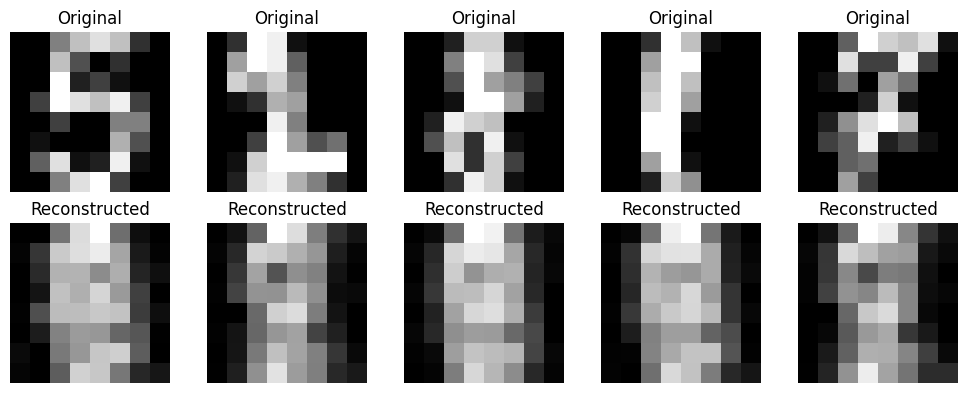

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, mean_squared_error

np.random.seed(42)
digits = load_digits()
X = digits.data.astype(np.float32) / 16.0
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Training samples:', X_train.shape)
print('Testing samples :', X_test.shape)

classifier = MLPClassifier(hidden_layer_sizes=(64,), max_iter=80, random_state=42, early_stopping=True)
classifier.fit(X_train, y_train)
predictions = classifier.predict(X_test)
print('Discriminative model accuracy:', round(accuracy_score(y_test, predictions), 4))

autoencoder = MLPRegressor(hidden_layer_sizes=(32, 8, 32), activation='relu', solver='adam', max_iter=120, random_state=42, early_stopping=True)
autoencoder.fit(X_train, X_train)
reconstructed = np.clip(autoencoder.predict(X_test[:5]), 0, 1)
print('Generative autoencoder reconstruction MSE:', round(mean_squared_error(X_test[:5], reconstructed), 4))

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(8, 8), cmap='gray')
    plt.axis('off')
    plt.title('Original')
    plt.subplot(2, 5, i + 6)
    plt.imshow(reconstructed[i].reshape(8, 8), cmap='gray')
    plt.axis('off')
    plt.title('Reconstructed')
plt.tight_layout()
plt.show()

## Observation
The classifier predicts a digit label, while the autoencoder reconstructs the visual pattern of the digit. The two models solve different tasks even though they use the same input data.

## Conclusion
Thus, discriminative and generative approaches were implemented and compared using handwritten digit images.